In [49]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from functools import reduce

In [36]:

BASE_DIR = "clean_dataset"

table_date = [
    'sales_pipeline'
]

date_columns = {
    name: ['engage_date', 'close_date']
    for name in table_date}


dfs = {}

for file in os.listdir(BASE_DIR):

    if file.endswith(".csv"):

        path = os.path.join(BASE_DIR, file)
        name = file.replace(".csv", "")

        dates = date_columns.get(name, None)

     
        df = pd.read_csv(
            path,
            parse_dates=dates
        )

        dfs[name] = df



In [37]:
df_sales_pipeline = dfs['sales_pipeline']
df_sales_teams = dfs['sales_teams']
df_products = dfs['products']
df_sales_pipeline_all_eng = df_sales_pipeline[~df_sales_pipeline['engage_date'].isna()]
df_sales_pipeline_Won = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Won']
df_sales_pipeline_Lost = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Lost']
df_sales_pipeline_Lost = pd.merge(df_sales_pipeline_Lost,df_products[['product','sales_price']],on ='product',how='left')
df_sales_pipeline_Lost.rename(
    columns={'sales_price': 'close_values_lost'},
    inplace=True
)
df_sales_pipeline_closed = df_sales_pipeline[~df_sales_pipeline['close_date'].isna()]
df_sales_pipeline_Pros = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Prospecting']
df_sales_pipeline_engaging = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Engaged']

In [ ]:
columns = df_sales_teams.columns

for column in columns:
    if column != "regional_office":
        print(f'{column} : {df_sales_teams[column].nunique()}')
    else :
        print(f'{column} : {df_sales_teams[column].nunique()} {list(df_sales_teams[column].unique())}')

print(f"Sales Agent with Opportunities : {df_sales_pipeline['sales_agent'].nunique()}")
sales_without_opportunities = np.setdiff1d((df_sales_teams['sales_agent'].unique()),(df_sales_pipeline['sales_agent'].unique()))
print(f"Sales Agent Without Opportunities : {len(sales_without_opportunities)}")
print(f"Sales Opportunity Participation Rate: {round(((df_sales_pipeline['sales_agent'].nunique()/df_sales_teams['sales_agent'].nunique())*100),0)}%")
display(list(sales_without_opportunities))
print('Total Agents by Manager')
display(pd.DataFrame(df_sales_teams.groupby('manager')['sales_agent'].nunique()))
print('Total Agents by Regional Office')
display(pd.DataFrame(df_sales_teams.groupby('regional_office')['sales_agent'].nunique()))



sales_agent : 35
manager : 6
regional_office : 3 ['Central', 'East', 'West']
Sales Agent with Opportunities : 30
Sales Agent Without Opportunities : 5
Sales Opportunity Participation Rate: 86.0%


['Carl Lin',
 'Carol Thompson',
 'Elizabeth Anderson',
 'Mei-Mei Johns',
 'Natalya Ivanova']

Total Agents by Manager


,sales_agent
manager,
Cara Losch,6
Celia Rouche,6
Dustin Brinkmann,5
Melvin Marxen,6
Rocco Neubert,6
Summer Sewald,6


Total Agents by Regional Office


,sales_agent
regional_office,
Central,11
East,12
West,12


data ini menujukan bahwa 86% dari sales agent yang ada memiliki riwayat opportunity yang ditawarkan kepada account, sementara 14% atau 5 dari 35 orang lainnya belum memiliki opportunity yang ditawarkan sama sekali

>> Monthly Agent Performance

In [39]:
monthly_sales_agent_engaged = df_sales_pipeline_all_eng.groupby([
    df_sales_pipeline_all_eng['engage_date'].dt.year.rename('year'),
    df_sales_pipeline_all_eng['engage_date'].dt.month.rename('month'),
    'sales_agent'
]).agg(
    total_engaging=('opportunity_id', 'nunique')
).reset_index()


monthly_sales_agent_won = df_sales_pipeline_Won.groupby([
    df_sales_pipeline_Won['close_date'].dt.year.rename('year'),
    df_sales_pipeline_Won['close_date'].dt.month.rename('month'),
    'sales_agent'
]).agg(
    total_won=('opportunity_id', 'nunique')
).reset_index()

agent_opportunity_summary = pd.merge(monthly_sales_agent_engaged,monthly_sales_agent_won,on = ['year','month','sales_agent'],how='outer')
monthly_sales_agent_summary = pd.merge(monthly_sales_agent_engaged.groupby(['year','month']).agg(sales_engaged = ('sales_agent','nunique')),
                monthly_sales_agent_won.groupby(['year','month']).agg(sales_won = ('sales_agent','nunique')),
                on = ['year','month'],how='outer').reset_index()

monthly_sales_agent_summary['year-month'] = pd.to_datetime(monthly_sales_agent_summary['year'].astype(str)+'-'+monthly_sales_agent_summary['month'].astype(str),format = '%Y-%m')
monthly_sales_agent_summary['y-m']= monthly_sales_agent_summary['year'].astype(str)+"-"+monthly_sales_agent_summary['month'].astype(str)

print(f"Average total won per month by agent : {agent_opportunity_summary['total_won'].mean().round(0)}")
print(f"Average total engaging per month by agent : {agent_opportunity_summary['total_engaging'].mean().round(0)}")
display(monthly_sales_agent_summary)
display(agent_opportunity_summary)


Average total won per month by agent : 14.0
Average total engaging per month by agent : 20.0


,year,month,sales_engaged,sales_won,year-month,y-m
0,2016,10,5,NaN,2016-10-01,2016-10
1,2016,11,29,NaN,2016-11-01,2016-11
2,2016,12,30,NaN,2016-12-01,2016-12
3,2017,1,30,NaN,2017-01-01,2017-1
4,2017,2,30,NaN,2017-02-01,2017-2
5,2017,3,30,30.0,2017-03-01,2017-3
6,2017,4,30,30.0,2017-04-01,2017-4
7,2017,5,30,30.0,2017-05-01,2017-5
8,2017,6,30,30.0,2017-06-01,2017-6
9,2017,7,30,30.0,2017-07-01,2017-7


,year,month,sales_agent,total_engaging,total_won
0,2016,10,Anna Snelling,1.0,NaN
1,2016,10,Darcel Schlecht,2.0,NaN
2,2016,10,Moses Frase,2.0,NaN
3,2016,10,Vicki Laflamme,1.0,NaN
4,2016,10,Zane Levy,1.0,NaN
...,...,...,...,...,...
419,2017,12,Versie Hillebrand,6.0,20.0
420,2017,12,Vicki Laflamme,6.0,31.0
421,2017,12,Violet Mclelland,7.0,19.0
422,2017,12,Wilburn Farren,3.0,10.0


rata-rata sales agent mampu mendapatkan 14 won opportunity dalam tiap bulannya, dan 20 engaging tiap bulannya

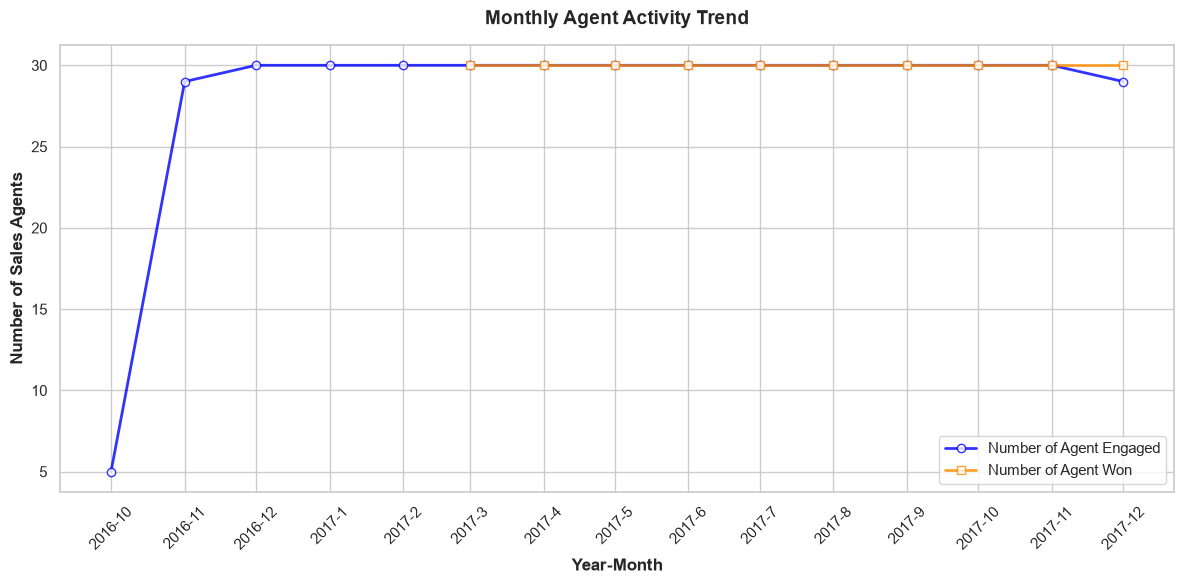

In [40]:
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")


plt.plot(
    monthly_sales_agent_summary['year-month'],
    monthly_sales_agent_summary['sales_engaged'],
    color='blue',
    linestyle='-',
    linewidth=2,
    marker='o',
    markersize=6,
    markerfacecolor='white',
    markeredgecolor='blue',
    alpha=0.8,
    label='Number of Agent Engaged'
)

plt.plot(
    monthly_sales_agent_summary['year-month'],
    monthly_sales_agent_summary['sales_won'],
    color='darkorange',
    linestyle='-',
    linewidth=2,
    marker='s',
    markersize=6,
    markerfacecolor='white',
    markeredgecolor='darkorange',
    alpha=0.8,
    label='Number of Agent Won'
)

plt.xlabel("Year-Month", fontsize=12, fontweight="bold")
plt.ylabel("Number of Sales Agents", fontsize=12, fontweight="bold")

plt.title(
    "Monthly Agent Activity Trend",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xticks(
    ticks=monthly_sales_agent_summary['year-month'],
    labels=monthly_sales_agent_summary['y-m'],
    rotation=45
)

plt.legend()
plt.tight_layout()
plt.show()

data diatas menujukkan bahwa agent mulai melakukan engage pada 2016-10 dengan total 5 agent, kemudian pada bulan 2016-12 30 agent melaukan engaged, dengan kondisi 30 agent tersebut baru mendapatkan win pertama mereka pada 2017-3

>> Agent Performance detail

In [ ]:
first_eng_agent= df_sales_pipeline_all_eng.groupby('sales_agent').agg(first_engage = ('engage_date','min')).reset_index()
first_win_agent = df_sales_pipeline_Won.groupby('sales_agent').agg(first_win = ('close_date','min')).reset_index()
first_date_agent = pd.merge(first_eng_agent,first_win_agent, on ='sales_agent', how='outer')
first_date_agent['day_diff'] = first_date_agent['first_win']-first_date_agent['first_engage']

df_sales_pipeline_Won['diff_days'] = (df_sales_pipeline_Won['close_date']-df_sales_pipeline_Won['engage_date']).dt.days
duration_to_win = df_sales_pipeline_Won.groupby('sales_agent').agg(avg_duration_to_win = ('diff_days','mean')).reset_index()
duration_to_win['avg_duration_to_win'] = round(duration_to_win['avg_duration_to_win'],0)

df_sales_pipeline_closed['diff_days'] = (df_sales_pipeline_closed['close_date']-df_sales_pipeline_closed['engage_date']).dt.days
duration_to_close = df_sales_pipeline_closed.groupby('sales_agent').agg(avg_duration_to_close = ('diff_days','mean')).reset_index()
duration_to_close['avg_duration_to_close'] = round(duration_to_close['avg_duration_to_close'],0)

df_agent_prop = df_sales_pipeline.groupby('sales_agent').agg(total_opportunity = ('opportunity_id','count')).reset_index()
df_agent_prop_pros = df_sales_pipeline_Pros[df_sales_pipeline_Pros['sales_agent']!='Unidentified'].groupby('sales_agent').agg(prospecting = ('opportunity_id','count')).reset_index()
df_agent_prop_eng = df_sales_pipeline_engaging.groupby('sales_agent').agg(engaging = ('opportunity_id','count')).reset_index()
df_agent_prop_won = df_sales_pipeline_Won.groupby('sales_agent').agg(won= ('opportunity_id','count'), sales_agent_value = ('close_value','sum')).reset_index()

df_agent_prop_lost = df_sales_pipeline_Lost.groupby('sales_agent').agg(lost = ('opportunity_id','count')).reset_index()

data_sales_agents = [
    df_agent_prop,
    df_agent_prop_pros,
    df_agent_prop_eng,
    df_agent_prop_won,
    df_agent_prop_lost,
    duration_to_close,
    duration_to_win,
    first_date_agent

]

df_sales_agents_summary = reduce(
    lambda df1, df2: pd.merge(
        df1, df2,
        on='sales_agent',
        how='outer'
    ),
    data_sales_agents
)
df_sales_agents_summary['overall_win_rate'] = round(((df_sales_agents_summary['won']/df_sales_agents_summary['total_opportunity'])*100),)

df_sales_agents_summary = df_sales_agents_summary.fillna(0)



In [75]:
print(" Duration of Agent get their first win since their first engaged")
display(first_date_agent.sort_values('day_diff',ascending=True))
print(f"average different days from first engaged opportunity to first win by agent : {round(((first_date_agent['day_diff'].dt.days).mean()),0)} days")
print(f"The shortes days from first engaged opportunity to first win by agent : {(first_date_agent['day_diff'].dt.days).min()} days")
print(f"The longest days from first engaded opportunity to first win by agent : {(first_date_agent['day_diff'].dt.days).max()} days")

 Duration of Agent get their first win since their first engaged


,sales_agent,first_engage,first_win,day_diff
13,Jonathan Berthelot,2016-12-02,2017-03-02,90 days
3,Cecily Lampkin,2016-11-25,2017-03-01,96 days
4,Corliss Cosme,2016-11-22,2017-03-01,99 days
7,Donn Cantrell,2016-11-20,2017-03-02,102 days
16,Lajuana Vencill,2016-11-18,2017-03-02,104 days
2,Cassey Cress,2016-11-16,2017-03-01,105 days
18,Marty Freudenburg,2016-11-15,2017-03-01,106 days
9,Garret Kinder,2016-11-13,2017-03-01,108 days
22,Reed Clapper,2016-11-12,2017-03-01,109 days
15,Kary Hendrixson,2016-11-12,2017-03-01,109 days


average different days from first engaged opportunity to first win by agent : 114.0 days
The shortes days from first engaged opportunity to first win by agent : 90 days
The longest days from first engaded opportunity to first win by agent : 132 days


data diatas menujukan bahwa rata-rata agent membutuhkan waktu 114 hari untuk akhrinya mendapatkan win opportunity mereka, dari hari pertama mereka melakukan engaging, yang paling cepat adalah 90 hari dan paling lama adalah 132 hari

In [44]:
display(df_sales_agents_summary.sort_values(['sales_agent_value','overall_win_rate','avg_duration_to_win'],ascending=[False,False,True]).head())
print(f" Average duration of sales agent to close the opportunity : {round((df_sales_agents_summary['avg_duration_to_close'].mean()),0)} days")
print(f" Average duration of sales agent to win the opportunity : {round((df_sales_agents_summary['avg_duration_to_win'].mean()),0)} days")
print(f" The shortes days to win the oppportunity : {min(df_sales_agents_summary['avg_duration_to_win'])} days")
print(f" The longest days to win the oppportunity : {max(df_sales_agents_summary['avg_duration_to_win'])} days")
print(f" Average opportunity win rate : {round((df_sales_agents_summary['overall_win_rate'].mean()),0)} %")
print(f" Average total value by agent : {df_sales_agents_summary['sales_agent_value'].mean().round(0)}")

,sales_agent,total_opportunity,prospecting,engaging,won,sales_agent_value,lost,avg_duration_to_close,avg_duration_to_win,first_engage,first_win,day_diff,overall_win_rate
6,Darcel Schlecht,747,111.0,0.0,349,1153214.0,204,46.0,49.0,2016-10-25,2017-03-04,130 days,47.0
26,Vicki Laflamme,451,0.0,0.0,221,478396.0,126,47.0,54.0,2016-10-30,2017-03-02,123 days,49.0
15,Kary Hendrixson,438,0.0,0.0,209,454298.0,126,50.0,53.0,2016-11-12,2017-03-01,109 days,48.0
2,Cassey Cress,346,0.0,0.0,163,450489.0,98,46.0,49.0,2016-11-16,2017-03-01,105 days,47.0
7,Donn Cantrell,275,0.0,0.0,158,445860.0,117,49.0,53.0,2016-11-20,2017-03-02,102 days,57.0


 Average duration of sales agent to close the opportunity : 48.0 days
 Average duration of sales agent to win the opportunity : 52.0 days
 The shortes days to win the oppportunity : 42.0 days
 The longest days to win the oppportunity : 65.0 days
 Average opportunity win rate : 49.0 %
 Average total value by agent : 333518.0


Total opportunities yang dipegang tiap agent berbeda halini yang kemudian berpotensi mempengaruhi jumlah closed atau value yang didapatkan tiap agent dan mempengaruhi overall win-rate karena perhitungan overal win-rate menggunakan total opportunites sebagai deminatornya, sales agent membutuhkan rata-rata waktu 48 hari untuk akhirnya menutup opportunity mereka, dan 52 hari untuk penutupan opportunity dengan hasil win, terdapat agent mampu menutup opportunity dengan status win hanya dalam 42 hari sejak opportunity tersebut engaged, dan terdapat agent dengan riwayat closed win dengan durasi 65 hari sejak opportunity tersebut di engaged. Rata-rata opportunity win rate dari sales agent adalah 49% artinya 49% dari keseluuhan opportunity yang di tangani oleh setiap agent berhasi ditutup dengan status win dengan rata-rata total valuenya adalah 333518 dollar. 

In [76]:
agent_x_account = pd.crosstab(
    df_sales_pipeline_all_eng['sales_agent'],
    df_sales_pipeline_all_eng['account']
)
agent_x_most_acount_engaged = pd.DataFrame({
    'Most Account Engaged': agent_x_account.idxmax(axis=1),
    'Number_of_Engaged' : agent_x_account.max(axis=1)
}).reset_index()


agent_x_account_won = pd.crosstab(
    df_sales_pipeline_Won['sales_agent'],
    df_sales_pipeline_Won['account']
)
agent_x_most_account_won = pd.DataFrame({
    'Most_Account_Won': agent_x_account_won.idxmax(axis=1),
    'Number_of_Won' : agent_x_account_won.max(axis=1)
}).reset_index()


agent_x_account_lost = pd.crosstab(
    df_sales_pipeline_Lost['sales_agent'],
    df_sales_pipeline_Lost['account']
)
agent_x_most_account_lost = pd.DataFrame({
    'Most_Account_Lost': agent_x_account_lost.idxmax(axis=1),
    'Number_of_Lost' : agent_x_account_lost.max(axis=1)
}).reset_index()

data_agent_x_account = [
    agent_x_most_acount_engaged,
    agent_x_most_account_won,
    agent_x_most_account_lost
]

agent_x_account_summary = reduce(
    lambda df1, df2: pd.merge(
        df1, df2,
        on='sales_agent',
        how='outer'
    ),
    data_agent_x_account
)

display(agent_x_account_summary )

,sales_agent,Most Account Engaged,Number_of_Engaged,Most_Account_Won,Number_of_Won,Most_Account_Lost,Number_of_Lost
0,Anna Snelling,Ron-tech,17,Hottechi,12,Funholding,11
1,Boris Faz,Zotware,13,Zotware,11,Konex,5
2,Cassey Cress,Plussunin,16,Plussunin,13,Donware,6
3,Cecily Lampkin,Isdom,12,Isdom,8,Streethex,5
4,Corliss Cosme,Donquadtech,15,Gekko & Co,10,Kan-code,8
5,Daniell Hammack,Konex,11,Konex,8,Massive Dynamic,6
6,Darcel Schlecht,Codehow,32,Codehow,19,Codehow,12
7,Donn Cantrell,Gekko & Co,16,Gekko & Co,11,Kan-code,8
8,Elease Gluck,Sonron,10,Dalttechnology,5,Green-Plus,5
9,Garret Kinder,Kan-code,10,Kan-code,8,Ontomedia,4


>> Segment Breakdown

In [45]:
df_agent_summary = pd.merge(df_sales_teams,df_sales_agents_summary,on='sales_agent',how = 'outer')
df_agent_summary = df_agent_summary[~df_agent_summary['total_opportunity'].isna()].reset_index(drop=True)
df_agent_manager = df_agent_summary.groupby('manager').agg(
    toal_agent = ('sales_agent','nunique'),
    average_total_opp=('total_opportunity', 'mean'),
    average_overall_win_rate=('overall_win_rate', 'mean'),
    average_won=('won', 'mean'),
    average_lost=('lost', 'mean'),
    avearge_duration_to_close=('avg_duration_to_close', 'mean'),
    average_account_value=('sales_agent_value', 'mean')
).reset_index()

df_agent_manager

,manager,toal_agent,average_total_opp,average_overall_win_rate,average_won,average_lost,avearge_duration_to_close,average_account_value
0,Cara Losch,5,192.8,51.0,96.0,53.0,49.2,226009.8
1,Celia Rouche,5,259.2,46.8,122.0,70.4,47.6,320779.4
2,Dustin Brinkmann,5,316.6,47.8,149.4,87.8,49.2,218872.6
3,Melvin Marxen,5,385.8,45.4,176.4,107.2,48.6,450386.0
4,Rocco Neubert,5,265.4,52.2,138.2,84.4,45.6,392109.0
5,Summer Sewald,5,340.2,49.0,165.6,91.8,48.4,392950.0


In [46]:
df_agent_regional_office = df_agent_summary.groupby('regional_office').agg(
    toal_agent = ('sales_agent','nunique'),
    average_total_opp=('total_opportunity', 'mean'),
    average_overall_win_rate=('overall_win_rate', 'mean'),
    average_won=('won', 'mean'),
    average_lost=('lost', 'mean'),
    average_duration_to_close=('avg_duration_to_close', 'mean'),
    average_account_value=('sales_agent_value', 'mean')
).reset_index()

df_agent_regional_office

,regional_office,toal_agent,average_total_opp,average_overall_win_rate,average_won,average_lost,average_duration_to_close,average_account_value
0,Central,10,351.2,46.6,162.9,97.5,48.9,334629.3
1,East,10,229.1,51.6,117.1,68.7,47.4,309059.4
2,West,10,299.7,47.9,143.8,81.1,48.0,356864.7


In [47]:
df_sales_agents_summary.sort_values(['sales_agent_value','avg_duration_to_win','overall_win_rate','lost'],ascending=[False,True,False,True]).head(5)

,sales_agent,total_opportunity,prospecting,engaging,won,sales_agent_value,lost,avg_duration_to_close,avg_duration_to_win,first_engage,first_win,day_diff,overall_win_rate
6,Darcel Schlecht,747,111.0,0.0,349,1153214.0,204,46.0,49.0,2016-10-25,2017-03-04,130 days,47.0
26,Vicki Laflamme,451,0.0,0.0,221,478396.0,126,47.0,54.0,2016-10-30,2017-03-02,123 days,49.0
15,Kary Hendrixson,438,0.0,0.0,209,454298.0,126,50.0,53.0,2016-11-12,2017-03-01,109 days,48.0
2,Cassey Cress,346,0.0,0.0,163,450489.0,98,46.0,49.0,2016-11-16,2017-03-01,105 days,47.0
7,Donn Cantrell,275,0.0,0.0,158,445860.0,117,49.0,53.0,2016-11-20,2017-03-02,102 days,57.0


In [48]:
display(df_sales_agents_summary.sort_values(['sales_agent_value','avg_duration_to_win','overall_win_rate'],ascending=[False,True,False]).tail(5))
df_sales_without_opp_record = df_sales_teams[df_sales_teams['sales_agent'].isin(sales_without_opportunities)]
df_sales_without_opp_record

,sales_agent,total_opportunity,prospecting,engaging,won,sales_agent_value,lost,avg_duration_to_close,avg_duration_to_win,first_engage,first_win,day_diff,overall_win_rate
16,Lajuana Vencill,311,40.0,0.0,127,194632.0,104,53.0,63.0,2016-11-18,2017-03-02,104 days,41.0
25,Versie Hillebrand,361,54.0,0.0,176,187693.0,88,47.0,52.0,2016-11-06,2017-03-02,116 days,49.0
21,Niesha Huffines,239,34.0,0.0,105,176961.0,70,53.0,55.0,2016-11-01,2017-03-02,121 days,44.0
28,Wilburn Farren,110,0.0,0.0,55,157640.0,24,52.0,57.0,2016-11-12,2017-03-07,115 days,50.0
27,Violet Mclelland,261,0.0,0.0,122,123431.0,71,52.0,58.0,2016-11-07,2017-03-04,117 days,47.0


,sales_agent,manager,regional_office
10,Mei-Mei Johns,Melvin Marxen,Central
16,Elizabeth Anderson,Cara Losch,East
22,Natalya Ivanova,Rocco Neubert,East
28,Carol Thompson,Celia Rouche,West
34,Carl Lin,Summer Sewald,West
